# GLEAM+GPM 論文資料重現：南美空中河流排水曲線（Fig. 2、Fig. 3）

Weng et al. (2026) *Hydrological regimes and drainage systems of aerial rivers across South America*, Nature Communications 17:9341.

這本筆記本只保留**和作者原始程式（`../Original_code_from_authors/Turningpoint_peak.ipynb`）一樣的算法**，用論文的 GLEAM+GPM 2006–2015 資料重現：

1. **資料**：pversion 版的 con / area 與固定分群檔
2. **724 格的經緯度**
3. **內插成 1000 點**：ln(面積) 內插
4. **分群**：論文的固定分群，用 k-means 與 Calinski–Harabasz 驗證
5. **Fig. 2**：分群地圖與排水曲線
6. **轉折點（Fig. 3）**：θ、θ′、median + 高斯平滑、第一個峰

最後的**附錄**整理了之前（用 ERA5 資料、照論文文字猜測）的做法錯在哪。

## 1. 資料

| 檔案 | 內容 |
|---|---|
| `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_con.npy` | (724, 725)，每列一個目標格點的**累積貢獻 C（%）**，來源格點依貢獻由大到小加入，0 → 100。**論文用的是這一版** |
| `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_area.npy` | (724, 725)，對應的**上風盆地面積**：0, 2.25, …, 1629，每步 2.25 = 一個 1.5° × 1.5° 格子的平方度，沒有依緯度修正 |
| `Original_code_from_authors/group_fix_4groups.txt` | 44 × 38 網格上的固定分群（0 = 非陸地，1–4 = G1–G4），非零格剛好 724 格，各群 186 / 168 / 195 / 175 格，和論文 Table 1 一樣 |

和論文文字不同、但原始程式就是這樣做的地方：

- **ln 取在面積上**，不是 Supp D 寫的 CDF：`ln(area + 0.225)` 對 con 線性內插。
- **面積單位是平方度**，圖上標成「10⁴ km²」（1 deg² 在赤道約 1.24 萬 km²，數值上接近）。
- 轉折點的 θ′ 是對**陣列索引**微分（不除以 dx），先 median filter 再高斯平滑，`find_peaks` 只設 prominence = 0.05，取**第一個峰**。論文 Methods 說的「第一、二峰相隔至少 10%」在程式裡沒有。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.collections import LineCollection
from itertools import permutations
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt, find_peaks
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import warnings
warnings.filterwarnings("ignore", message="Glyph .* missing")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = ["PingFang TC", "Heiti TC", "Arial Unicode MS", "Microsoft JhengHei",
                                   "Noto Sans CJK TC", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

GG_SRC = "../Original_code_from_authors/"
gg_con   = np.load(GG_SRC + "gleamgpm_0615_pversion_allpoint_con.npy",  allow_pickle=False)   # (724, 725)，%
gg_area  = np.load(GG_SRC + "gleamgpm_0615_pversion_allpoint_area.npy", allow_pickle=False)   # (724, 725)，deg²
gg_fix   = np.loadtxt(GG_SRC + "group_fix_4groups.txt")                                       # (44, 38)，0–4

print("con :", gg_con.shape, f"{gg_con.min():.1f}–{gg_con.max():.1f} %，每列單調遞增:", bool((np.diff(gg_con, axis=1) >= 0).all()))
print("area:", gg_area.shape, f"0–{gg_area.max():.0f} deg²，每步", np.unique(np.diff(gg_area[0])))
print(f"第一個來源格點的貢獻中位數：{np.median(gg_con[:, 1]):.1f}%")
print("group 檔:", gg_fix.shape, " 非零格數", int((gg_fix != 0).sum()), " 各群", [int((gg_fix == k).sum()) for k in range(1, 5)])
gg_n = len(gg_con)

con : (724, 725) 0.0–100.0 %，每列單調遞增: True
area: (724, 725) 0–1629 deg²，每步 [2.25]
第一個來源格點的貢獻中位數：30.3%
group 檔: (44, 38)  非零格數 724  各群 [186, 168, 195, 175]


## 2. 724 格的經緯度

原始程式（`Turningpoint_peak.ipynb` cell 3 第 5–11 行）用 `for i in range(44): for j in range(38):` 依序取出 `group_fix_4groups.txt` 的非零格，這個順序就是 npy 的列順序：**北 → 南、每列西 → 東**。格點中心用 Zenodo 程式的網格：lat = 15, 13.5, …, −49.5；lon = −85.5, −84, …, −30（44 × 38，和 Supp H 寫的一樣）。

In [2]:
gg_glat = np.arange(-49.5, 16, 1.5)[::-1]       # 15 → −49.5
gg_glon = np.arange(-85.5, -29, 1.5)            # −85.5 → −30
gg_ii, gg_jj = np.nonzero(gg_fix)               # row-major：北 → 南、每列西 → 東
gg_lat, gg_lon = gg_glat[gg_ii], gg_glon[gg_jj]
gg_group = gg_fix[gg_ii, gg_jj].astype(int) - 1  # 0..3 → G1..G4（論文的固定分群）

gg_sor = int(np.argmin((gg_lat + 12.5) ** 2 + (gg_lon + 55.7) ** 2))
print(f"緯度 {gg_lat.min()} ~ {gg_lat.max()}，經度 {gg_lon.min()} ~ {gg_lon.max()}")
print(f"Sorriso（12.5°S, 55.7°W）→ 第 {gg_sor} 列，格點 ({gg_lat[gg_sor]}, {gg_lon[gg_sor]})，G{gg_group[gg_sor] + 1}")

緯度 -48.0 ~ 13.5，經度 -85.5 ~ -36.0
Sorriso（12.5°S, 55.7°W）→ 第 362 列，格點 (-12.0, -55.5)，G3


## 3. 內插成 1000 點（原始程式 `Turningpoint_peak.ipynb` cell 5 第 11–22 行）

```python
a = np.min(area[area > 0]) / 10                       # 0.225，避免 log(0)
f = interp1d(con, np.log(area + a), kind="linear", fill_value="extrapolate")
x = np.linspace(min(con), max(con), 1000)              # 0–100%
y = np.exp(f(x)) - a
```

也就是在 (C, ln A) 上線性內插，C 在原尺度等距取 1000 點。這和 Supplementary D 的文字（對 CDF 取 ln）不同，這裡以作者的程式為準。

In [3]:
def gg_interp(con, area):
    a = np.min(area[area > 0]) / 10
    f = interp1d(con, np.log(area + a), kind="linear", fill_value="extrapolate")
    x = np.linspace(con.min(), con.max(), 1000)
    return x, np.exp(f(x)) - a

gg_X, gg_Ai = map(np.array, zip(*[gg_interp(c, a) for c, a in zip(gg_con, gg_area)]))       # (724, 1000)
gg_i50 = np.argmin(np.abs(gg_X[0] - 50))
print(gg_Ai.shape, f" x 範圍 {gg_X.min():.1f}–{gg_X.max():.1f}%",
      f" C=50% 面積中位數 {np.median(gg_Ai[:, gg_i50]):.0f} deg²")

(724, 1000)  x 範圍 0.0–100.0%  C=50% 面積中位數 21 deg²


## 4. 分群：論文的固定分群，用 k-means 驗證

原始程式直接讀 `group_fix_4groups.txt`，沒有附 k-means 和 CH 的程式。這裡用 Methods 的寫法驗證它是怎麼來的：等距取 100 點的**線性面積**當特徵（不取 log、不標準化），CH 測 k = 2–11，k-means 4 群（`n_init=50, random_state=0`），再和固定分群比對。k-means 的群編號是隨機的，所以比對時取 4 群所有對應方式中一致比例最高的那個。

CH 分數：
  k =  2    2,220
  k =  3    2,463
  k =  4    2,810
  k =  5    2,814
  k =  6    2,754
  k =  7    2,615
  k =  8    2,543
  k =  9    2,572
  k = 10    2,611
  k = 11    2,594

k-means 4 群和固定分群一致的比例: 96.0%
k-means 各群格數（由小到大）: [165, 177, 189, 193]
論文固定分群各群格數:         [186, 168, 195, 175]


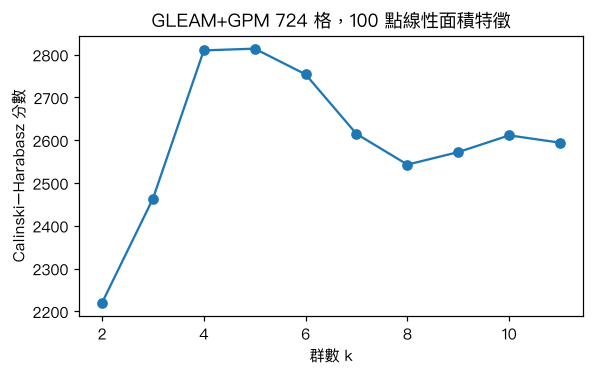

In [4]:
gg_idx100 = np.linspace(0, 999, 100).astype(int)
gg_feat = gg_Ai[:, gg_idx100]                    # 100 點線性面積（deg²）

def gg_agree(lab, ref=gg_group, k=4):
    return max(np.mean(np.array(p)[lab] == ref) for p in permutations(range(k)))

gg_ks = range(2, 12)
gg_ch = [calinski_harabasz_score(gg_feat, KMeans(k, n_init=20, random_state=0).fit_predict(gg_feat)) for k in gg_ks]
gg_km = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(gg_feat)

print("CH 分數：")
for k, v in zip(gg_ks, gg_ch):
    print(f"  k = {k:2d}  {v:7,.0f}")
print(f"\nk-means 4 群和固定分群一致的比例: {gg_agree(gg_km)*100:.1f}%")
print("k-means 各群格數（由小到大）:", sorted(np.bincount(gg_km).tolist()))
print("論文固定分群各群格數:        ", [int((gg_group == g).sum()) for g in range(4)])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(gg_ks, gg_ch, "o-")
ax.set_xlabel("群數 k"); ax.set_ylabel("Calinski–Harabasz 分數")
ax.set_title("GLEAM+GPM 724 格，100 點線性面積特徵")
plt.tight_layout(); plt.show()

## 5. Fig. 2 重現

(a) 把論文的固定分群畫回 1.5° 格子；(b) 曲線，x 是累積貢獻 0–100%，y 是面積（論文標成 10⁴ km²，實際是平方度），0–1000，G4 先畫在最底層。配色取自論文 Fig. 2。

findfont: Failed to find font weight bold for PingFang TC, now using 600.


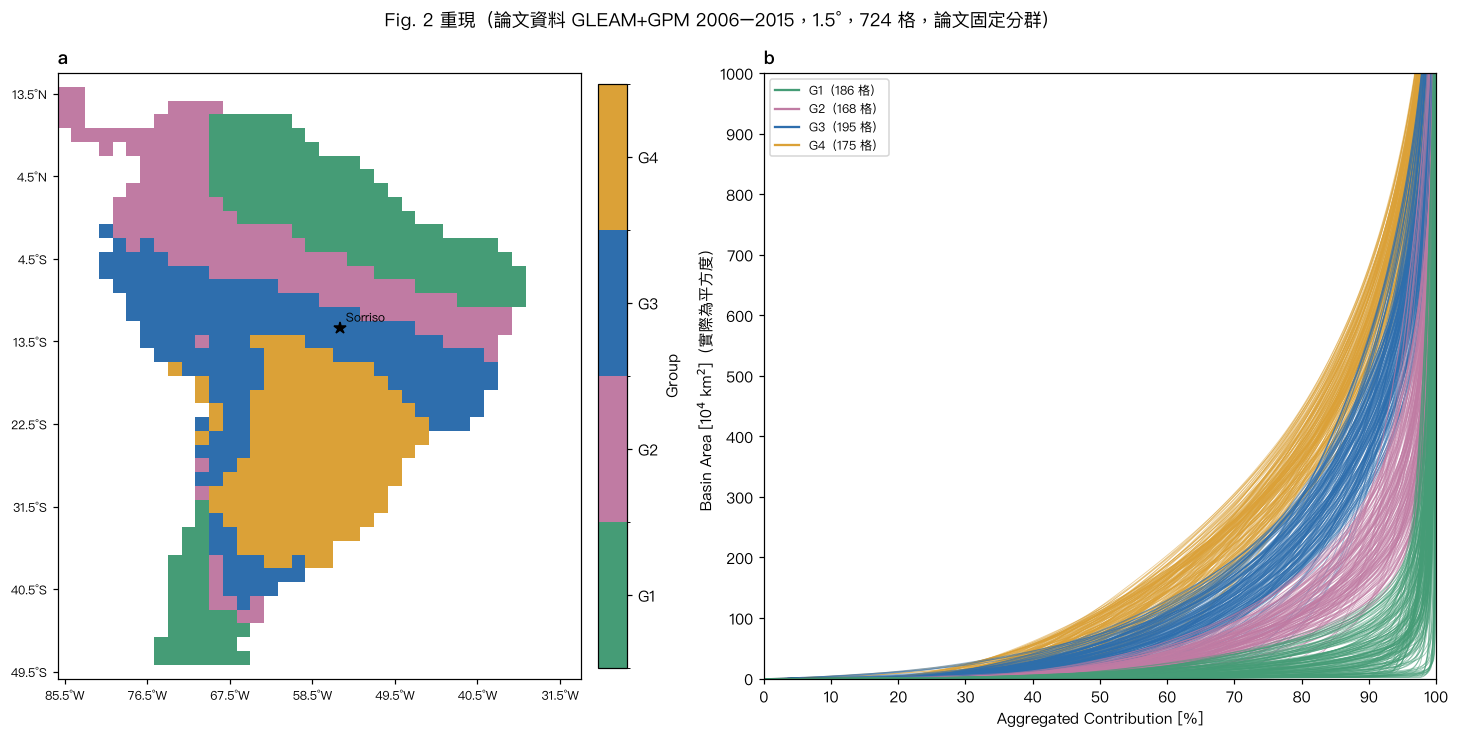

In [5]:
GG_COLORS = ["#459C76", "#C07BA3", "#2E6EAD", "#DBA137"]
gg_cmap = ListedColormap(GG_COLORS); gg_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), 4)
gg_grid = np.where(gg_fix > 0, gg_fix - 1, np.nan)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 6.8), gridspec_kw={"width_ratios": [1, 1.15]})
pm = axa.pcolormesh(gg_glon, gg_glat, gg_grid, cmap=gg_cmap, norm=gg_norm, shading="nearest")
axa.set_aspect("equal"); axa.set_xlim(-86.25, -29.25); axa.set_ylim(-50.25, 15.75)
axa.set_xticks(np.arange(-85.5, -30, 9)); axa.set_yticks(np.arange(-49.5, 14, 9))
axa.set_xticklabels([f"{-v:g}°W" for v in np.arange(-85.5, -30, 9)], fontsize=8)
axa.set_yticklabels([f"{abs(v):g}°{'S' if v < 0 else 'N'}" for v in np.arange(-49.5, 14, 9)], fontsize=8)
cb = fig.colorbar(pm, ax=axa, ticks=range(4), fraction=0.05, pad=0.03)
cb.ax.set_yticklabels(["G1", "G2", "G3", "G4"]); cb.set_label("Group")
axa.plot(gg_lon[gg_sor], gg_lat[gg_sor], "k*", ms=8)
axa.annotate("Sorriso", (gg_lon[gg_sor], gg_lat[gg_sor]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axa.set_title("a", loc="left", fontweight="bold")

for g in [3, 2, 1, 0]:
    m = gg_group == g
    segs = [np.column_stack([x_, a_]) for x_, a_ in zip(gg_X[m], gg_Ai[m])]
    axb.add_collection(LineCollection(segs, colors=GG_COLORS[g], linewidths=0.6, alpha=0.5))
for g in range(4):
    axb.plot([], [], c=GG_COLORS[g], lw=1.5, label=f"G{g+1}（{(gg_group == g).sum()} 格）")
axb.set_xlim(0, 100); axb.set_ylim(0, 1000)
axb.set_xticks(range(0, 101, 10)); axb.set_yticks(range(0, 1001, 100))
axb.set_xlabel("Aggregated Contribution [%]")
axb.set_ylabel("Basin Area [10$^4$ km$^2$]（實際為平方度）")
axb.legend(loc="upper left", fontsize=8)
axb.set_title("b", loc="left", fontweight="bold")
fig.suptitle("Fig. 2 重現（論文資料 GLEAM+GPM 2006–2015，1.5°，724 格，論文固定分群）")
plt.tight_layout()
plt.savefig("Fig2_GLEAMGPM.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. 轉折點（Fig. 3，原始程式 cell 1、5、12、20）

1. **斜率**：自訂 `slope()`，中間點用前後各隔 2 點的中央差分 $(y_{i+2}-y_{i-2})/(x_{i+2}-x_{i-2})$，兩端改用較短的差分。y 先除以 10（原註解：讓 y 軸和 x 軸的尺度一樣），x 是 %（0–100）。
2. **θ**：`np.arctan(slope) * 180 / np.pi`，單位是度。
3. **θ′**：`np.gradient(θ)`，對陣列索引微分，沒有除以 dx。
4. **平滑**：`medfilt(kernel_size=15)` 後接 `gaussian_filter1d(sigma=10)`。
5. **找峰**：`find_peaks(prominence=0.05)`，取**第一個峰**；找不到峰的曲線不列入。

論文：G1 90–95%、G2 60–75%、G3 40–55%、G4 30–40%，Sorriso 47%。

In [6]:
def gg_slope(x, y):
    s = np.empty(len(x))
    s[0] = (y[1] - y[0]) / (x[1] - x[0])
    s[1] = (y[2] - y[0]) / (x[2] - x[0])
    s[-2] = (y[-1] - y[-3]) / (x[-1] - x[-3])
    s[-1] = (y[-1] - y[-2]) / (x[-1] - x[-2])
    s[2:-2] = (y[4:] - y[:-4]) / (x[4:] - x[:-4])
    return s

def gg_turning(x, y):
    theta = np.degrees(np.arctan(gg_slope(x, y / 10)))
    r = gaussian_filter1d(medfilt(np.gradient(theta), kernel_size=15), sigma=10)
    peaks, _ = find_peaks(r, prominence=0.05)
    return r, x[peaks]

gg_res = [gg_turning(x, y) for x, y in zip(gg_X, gg_Ai)]
gg_r = np.array([r for r, _ in gg_res])
gg_peaks = [p for _, p in gg_res]
gg_tp = np.array([p[0] if len(p) else np.nan for p in gg_peaks])          # 第一個峰
gg_npk = np.array([len(p) for p in gg_peaks])

paper = ["90–95", "60–75", "40–55", "30–40"]
print("        論文     中位數   平均    Q1–Q3          無峰  峰數≥3")
for g in range(4):
    m = gg_group == g; v = gg_tp[m]
    print(f"G{g+1}  {paper[g]:>7}  {np.nanmedian(v):7.1f}  {np.nanmean(v):6.1f}  "
          f"{np.nanpercentile(v, 25):5.1f}–{np.nanpercentile(v, 75):5.1f}  {np.isnan(v).sum():6d}  {(gg_npk[m] >= 3).sum():6d}")
print(f"\nSorriso：轉折點 {gg_tp[gg_sor]:.1f}%（論文 47%），對應面積 {np.interp(gg_tp[gg_sor], gg_X[gg_sor], gg_Ai[gg_sor]):.0f} deg²")

        論文     中位數   平均    Q1–Q3          無峰  峰數≥3
G1    90–95     95.3    92.7   91.3– 96.9       5      15
G2    60–75     68.6    69.8   60.6– 79.2       0      87
G3    40–55     48.0    49.4   38.1– 58.7       0     109
G4    30–40     35.5    35.8   29.6– 42.8       0      70

Sorriso：轉折點 46.7%（論文 47%），對應面積 35 deg²


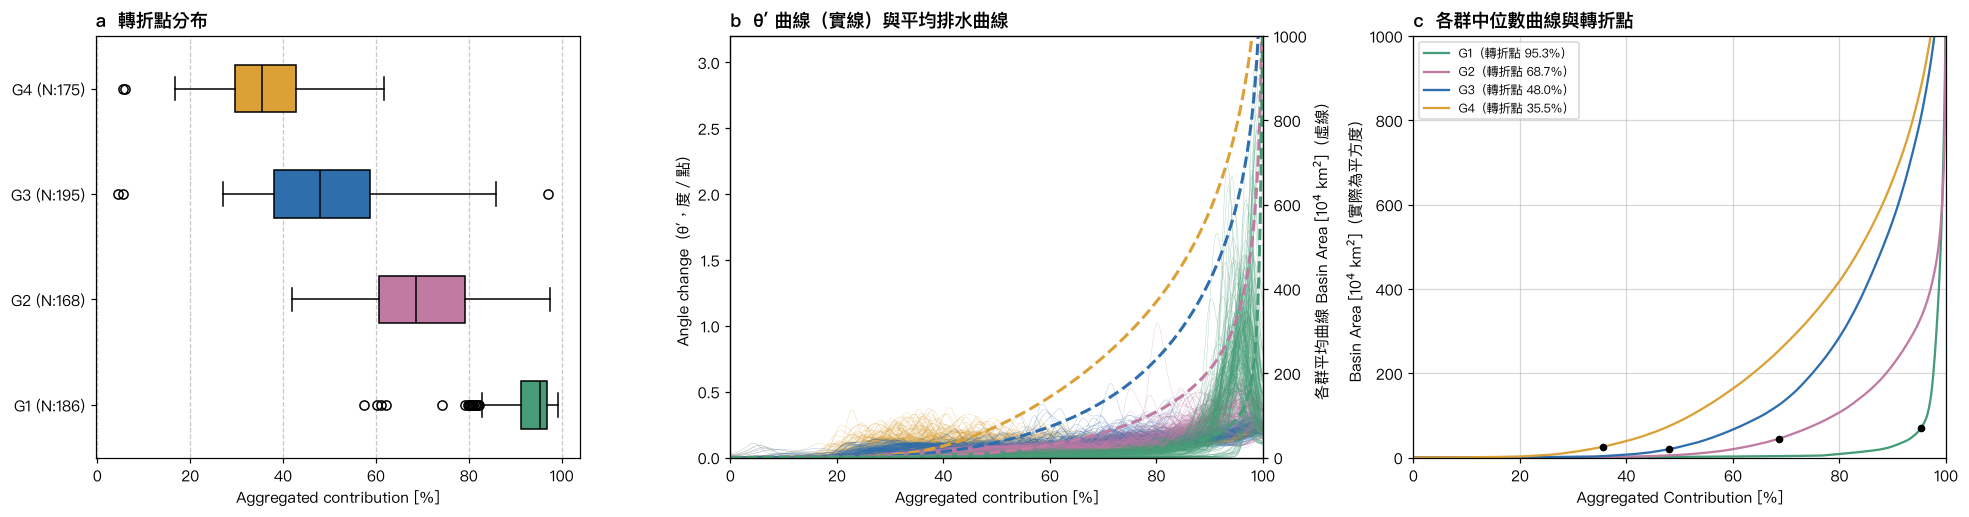

In [7]:
fig, (axa, axb, axc) = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})

# (a) 各群第一個峰的箱形圖（論文 Fig. 3a，原始程式 cell 12）
data = [gg_tp[(gg_group == g) & ~np.isnan(gg_tp)] for g in range(4)]
box = axa.boxplot(data, orientation="horizontal", patch_artist=True)
for patch, c in zip(box["boxes"], GG_COLORS):
    patch.set_facecolor(c)
for med in box["medians"]:
    med.set_color("black")
axa.set_yticks(range(1, 5)); axa.set_yticklabels([f"G{g+1} (N:{(gg_group == g).sum()})" for g in range(4)])
axa.set_xlabel("Aggregated contribution [%]"); axa.grid(axis="x", ls="--", alpha=0.7)
axa.set_title("a  轉折點分布", loc="left", fontweight="bold")

# (b) 各群 θ′ 曲線（論文 Fig. 3b，原始程式 cell 7–10）與各群平均曲線（右軸）
axb2 = axb.twinx()
for g in [3, 2, 1, 0]:
    m = gg_group == g
    for x_, r_ in zip(gg_X[m], gg_r[m]):
        axb.plot(x_, r_, c=GG_COLORS[g], lw=0.3, alpha=0.4)
    axb2.plot(gg_con[m].mean(0), gg_area[m].mean(0), c=GG_COLORS[g], lw=2, ls="--")
axb.set_xlim(0, 100); axb.set_ylim(0, 3.2)
axb.set_xlabel("Aggregated contribution [%]"); axb.set_ylabel("Angle change（θ′，度／點）")
axb2.set_ylim(0, 1000); axb2.set_ylabel("各群平均曲線 Basin Area [10$^4$ km$^2$]（虛線）")
axb.set_title("b  θ′ 曲線（實線）與平均排水曲線", loc="left", fontweight="bold")

# (c) 各群轉折點最接近中位數的那條曲線與轉折點（論文 Fig. S5，原始程式 cell 20）
for g in range(4):
    m = np.nonzero((gg_group == g) & ~np.isnan(gg_tp))[0]
    med = np.nanmedian(gg_tp[m])
    k = m[np.argmin(np.abs(gg_tp[m] - med))]          # 轉折點最接近該群中位數的那條曲線
    axc.plot(gg_X[k], gg_Ai[k], c=GG_COLORS[g], lw=1.5, label=f"G{g+1}（轉折點 {gg_tp[k]:.1f}%）")
    axc.plot(gg_tp[k], np.interp(gg_tp[k], gg_X[k], gg_Ai[k]), "ko", ms=4)
axc.set_xlim(0, 100); axc.set_ylim(0, 1000)
axc.set_xlabel("Aggregated Contribution [%]"); axc.set_ylabel("Basin Area [10$^4$ km$^2$]（實際為平方度）")
axc.legend(fontsize=8); axc.grid(alpha=0.5)
axc.set_title("c  各群中位數曲線與轉折點", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("Fig3_GLEAMGPM.png", dpi=200, bbox_inches="tight")
plt.show()

## 附錄：之前的做法錯在哪

這本筆記本之前還有一大段用 ERA5 資料、照論文文字猜測細節的分析（完整舊版備份在 `_backup/Reproduce_before_cleanup.ipynb`）。拿到作者的原始程式和 pversion 資料後，對照出下面這些差別。

### (a) 資料

**ERA5 的三個 nc 檔不是論文的資料**

| | 論文 | `data/drainage_curves_*.nc` |
|---|---|---|
| 驅動資料 | GPM IMERG 降雨、GLEAM v3.6a 蒸發、ERA-Interim 風與濕度 | ERA5 |
| 期間 | 2006–2015 | 2020–2025 |
| 解析度 | 1.5°，南美 724 格 | 0.25°，南美約 2.5 萬格 |
| 追蹤範圍 | 只有南美（30°W–85.5°W、15°N–49.5°S） | 全球 |
| 面積單位 | 平方度（格數 × 2.25） | km²，依緯度計算 |
| 曲線尾巴 | 最多 1629 deg² | C 接近 100% 時達 10⁷–10⁸ km² |

所以 ERA5 版的分群和轉折點本來就對不上論文：線性面積特徵會被超長的尾巴主導，CH 最高落在 k = 3 或 5，地圖上論文的 G3 會整群併進 G4。

**兩版 con 檔**：`data/gleamgpm_0615_allpoint_con.npy` 和論文用的 `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_con.npy` 的 area 完全相同，但 con 每一列都不同。用 data/ 版跑同樣的算法：

| | pversion（論文） | data/ 版 |
|---|---|---|
| 第 1 個來源格點佔比（中位數） | 30.3% | 10.2% |
| 有效來源格點數（中位數） | 10 | 51 |
| k-means 和固定分群一致 | 96.0% | 83.3% |
| CH 最高 | k = 5（和 k = 4 只差 0.1%） | k = 6 |
| 轉折點中位數 G1 / G2 / G3 / G4 | 95.3 / 68.6 / 48.0 / 35.5% | 89.5 / 49.3 / 23.0 / 3.6% |

**pversion 是什麼**

- 文件裡寫的：論文正文和補充材料都沒有提到兩個版本的 con，也沒有說明 pversion。原始程式只在 cell 3 第 2–3 行讀了 pversion 檔，沒有註解。
- 從數據確定的：兩版都是貢獻由大到小排序。pversion 的貢獻更集中在前幾個來源，99.7% 的數值 pversion ≥ data/ 版。它不是同一組貢獻換排序，也不是取某個次方，也不是多插入一個來源（例如局地再循環）。
- 推測：pversion 可能是用不同的方式算每個來源格點的貢獻（權重或分母不同，「p」也許是 precipitation），或是不同版本的追蹤設定。需要問作者。可以確定的是，論文發表的轉折點和分群都只有用 pversion 才重現得出來。

### (b) 轉折點算法

| 步驟 | 作者原始程式（本筆記本） | 之前的猜測 |
|---|---|---|
| 軸的尺度 | x = %（0–100），y = 平方度 ÷ 10 | 每條曲線各自縮放到 0–1，或用 10⁴ / 10⁵ km² |
| 斜率 | 前後各隔 2 點的中央差分，兩端另外處理 | `np.gradient` |
| θ 單位 | 度 | 弧度 |
| θ′ | `np.gradient(θ)`，對索引，不除以 dx | 除以 dx（每 %），所以同樣的 0.05 門檻意義差約 5–6 倍 |
| 平滑 | 對 θ′：`medfilt(15)` 再 `gaussian_filter1d(σ=10)` | 對曲線 y：只有高斯 σ = 10 |
| 找峰 | `find_peaks(prominence=0.05)`，不設 distance | 另外加了 distance = 10% C（照 Methods 文字） |
| 取峰 | 第一個峰 | 第一個峰和最大峰都試過 |

每條曲線各自縮放到 0–1 時，所有曲線形狀變得很像，最大峰全落在 85–95%，排不出 G1 > G2 > G3 > G4。

### (c) k-means 特徵：線性 vs log

| 特徵（pversion） | 和固定分群一致 | CH 最高 |
|---|---|---|
| 100 點線性面積，不標準化 | 96.0% | k = 5（≈ k = 4） |
| 100 點 log10 面積 | 60.1% | k = 5 |

論文 Methods 沒寫要不要取 log，正確的是線性面積。

### (d) ln 取在哪一軸

Supp D 的文字寫「對 CDF 取 ln」，所以之前把 ln 放在累積貢獻 C 上；原始程式其實是 ln(面積 + 0.225) 對 C 線性內插。對分群影響很小（之前用 ERA5 比較，只有 0.3% 的格點換群），但會影響曲線前段形狀和轉折點。

### (e) 經緯度

拿到 `group_fix_4groups.txt` 之前，是用 ERA5 曲線加動態規劃猜 724 列各在哪一格：選出的格子有 710 / 724 和正確的一樣，但順序錯位，只有 322 列真的對到正確位置，所以當時的地圖有不少位移。現在直接用作者的檔案。